# 00 — เริ่มต้นที่นี่: เรากำลังทำอะไร และทำถึงไหนแล้ว

สมุดเล่มนี้เป็น **หน้าปกของการทดลองจริง** ไม่ใช่เว็บไซต์ประชาสัมพันธ์ และไม่ใช่การเทรนรอบใหม่

เมื่อกดรัน เซลล์จะอ่านหลักฐานที่มีอยู่แล้วจาก repository และ `E:\blp\sleep_stage_reproduction` เพื่อสรุปว่า

1. บทความต้นฉบับกำหนดอะไร
2. เราสร้างข้อมูลและรันอะไรจริงแล้ว
3. ผลใดเป็นเพียง pilot และยังเทียบกับบทความไม่ได้
4. ขั้นใดยังติด gate หรือยังไม่เริ่ม

> กติกาการอ่าน: สีเขียว = มีหลักฐานว่าสำเร็จ, สีเหลือง = เตรียมพร้อมบางส่วน, สีแดง = ถูก block/ล้มเหลว, สีเทา = ยังไม่เริ่ม

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "paper_faithful").is_dir())
sys.path.insert(0, str(ROOT / "walkthrough"))

import matplotlib.pyplot as plt
import numpy as np
from walkthrough_lib import *

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print(f"Project root : {PROJECT_ROOT}")
print(f"Bulk artifacts: {BULK_ROOT}")

Project root : C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction
Bulk artifacts: E:\blp\sleep_stage_reproduction


## 1. ตรวจว่าเครื่องนี้เห็นหลักฐานครบหรือไม่

เส้นทางต่อไปนี้เป็นแหล่งข้อมูลจริง เซลล์นี้ตรวจเฉพาะการมีอยู่ของไฟล์ ไม่แก้ไขไฟล์ใด ๆ

In [2]:
health = path_health()
print_records(health, ["artifact", "exists", "path"])
assert health[0]["exists"], "เปิด notebook จาก repository ไม่ถูกตำแหน่ง"

artifact                    | exists | path                                                                                                                                            
----------------------------+--------+-------------------------------------------------------------------------------------------------------------------------------------------------
project                     | True   | C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction                                                                           
local_edf                   | True   | C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\data\sleep-edf                                                            
full_preprocessing_manifest | True   | E:\blp\sleep_stage_reproduction\preprocessed\sleep-edfx\1.0.0\sleep-cassette\paper_faithful_v3_full_20260820\manifests\preprocessing_result.json
full_sst_cache              | True   | E:\blp\sleep_stage_reproduction\sst_cache

## 2. ภาพรวมสถานะจากหลักฐานล่าสุด

`r19 cap128` หมายถึงใช้ไม่เกิน 128 epochs ต่อ split เพื่อพิสูจน์ว่า pipeline ทำงานได้ ไม่ใช่การรัน full numerical reproduction

milestone                   | status      | evidence                                                           
----------------------------+-------------+--------------------------------------------------------------------
Source/protocol lock        | complete    | PAPER_TEXT_V1 + source manifests                                   
Full preprocessing          | complete    | 153 records / 78 subjects / 194,655 epochs                         
Full SST cache              | complete    | published cache manifest on E:                                     
r19 cap128, two seeds       | complete    | completed runs: 2/2                                                
Subject-held-out pilot      | blocked     | live resource gate refused: available physical memory below 4096 MB
Full numerical reproduction | not_started | ยังไม่มีผลเต็มที่ตรวจรับแล้ว                                       


C:\Users\Acer\AppData\Local\Temp\ipykernel_40700\3454523773.py:26: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer\AppData\Local\Temp\ipykernel_40700\3454523773.py:26: UserWarning: Glyph 9940 (\N{NO ENTRY}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9940 (\N{NO ENTRY}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


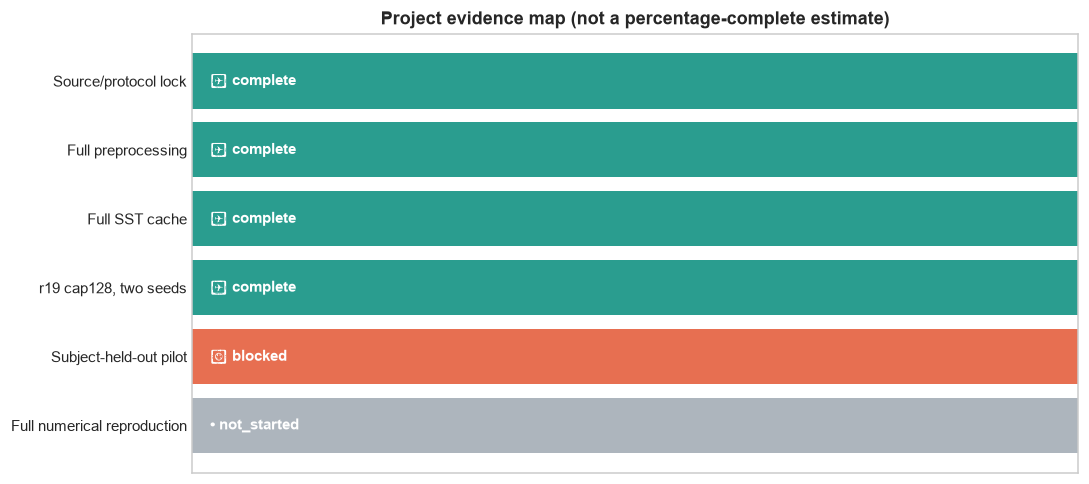

In [3]:
cohort = full_cohort_summary()
r19 = r19_runs()
gate = subject_gate_summary()

overview = [
    {"milestone": "Source/protocol lock", "status": "complete", "evidence": "PAPER_TEXT_V1 + source manifests"},
    {"milestone": "Full preprocessing", "status": cohort["status"], "evidence": f"{cohort['recordings']} records / {cohort['subjects']} subjects / {cohort['epochs']:,} epochs"},
    {"milestone": "Full SST cache", "status": "complete" if CACHE_ROOT.exists() else "missing", "evidence": "published cache manifest on E:"},
    {"milestone": "r19 cap128, two seeds", "status": "complete" if len(r19) == 2 and all(x['status'] == 'completed' for x in r19) else "prepared", "evidence": f"completed runs: {sum(x['status']=='completed' for x in r19)}/2"},
    {"milestone": "Subject-held-out pilot", "status": gate["status"], "evidence": gate["reason"]},
    {"milestone": "Full numerical reproduction", "status": "not_started", "evidence": "ยังไม่มีผลเต็มที่ตรวจรับแล้ว"},
]
print_records(overview, ["milestone", "status", "evidence"])

fig, ax = plt.subplots(figsize=(10, 4.5))
names = [row["milestone"] for row in overview]
colors = [STATUS_COLORS.get(row["status"], "#adb5bd") for row in overview]
ax.barh(range(len(names)), [1] * len(names), color=colors)
ax.set_yticks(range(len(names)), names)
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.invert_yaxis()
ax.set_title("Project evidence map (not a percentage-complete estimate)")
for i, row in enumerate(overview):
    ax.text(0.02, i, status_badge(row["status"]), va="center", color="white", weight="bold")
plt.tight_layout()
plt.show()

## 3. เป้าหมายของบทความ เทียบกับสถานะของเรา

ตัวเลข 83% เป็นผลที่บทความรายงานจาก protocol เต็ม ส่วนผล r19 เป็น **pilot ที่ตัดข้อมูลเหลือ cap128** จึงวางไว้ให้เห็นระยะห่าง แต่ห้ามสรุปว่าโมเดลเราดีกว่าหรือแย่กว่าบทความจากกราฟเดียว

In [4]:
protocol = paper_protocol()
comparison = [
    {"item": "Dataset", "paper": "Sleep-EDF full cohort", "ours": f"full cohort prepared: {cohort['subjects']} subjects"},
    {"item": "Input", "paper": "Fpz-Cz, 100 Hz, 30 s", "ours": f"{protocol['dataset']['signal']}, {protocol['dataset']['sampling_hz']} Hz"},
    {"item": "Reported accuracy", "paper": "83%", "ours": "ยังไม่มี full accepted result"},
    {"item": "Latest runnable evidence", "paper": "full experiment", "ours": "r19 cap128, 2 seeds completed"},
    {"item": "Subject-held-out", "paper": "not the 83% split", "ours": f"{gate['status']}; training_started={gate['training_started']}"},
]
print_records(comparison, ["item", "paper", "ours"])

item                     | paper                 | ours                             
-------------------------+-----------------------+----------------------------------
Dataset                  | Sleep-EDF full cohort | full cohort prepared: 78 subjects
Input                    | Fpz-Cz, 100 Hz, 30 s  | Fpz-Cz, 100 Hz                   
Reported accuracy        | 83%                   | ยังไม่มี full accepted result    
Latest runnable evidence | full experiment       | r19 cap128, 2 seeds completed    
Subject-held-out         | not the 83% split     | blocked; training_started=False  


## 4. อ่านเล่มต่อไปตามลำดับ

- `01_data_and_eeg.ipynb` — เห็นสัญญาณ EEG จริงและการกระจาย sleep stage
- `02_sst_representation.ipynb` — เห็น SST tensor จริงที่ป้อนโมเดล
- `03_model_and_protocol.ipynb` — เข้าใจ 3 ขั้นของการฝึกและจุดที่เราปรับให้เข้ากับฮาร์ดแวร์
- `04_results_and_next_steps.ipynb` — อ่านผลจริง confusion matrix ข้อจำกัด และงานถัดไป
- `05_embedding_and_transform_visuals.ipynb` — ดู sliding DFT/SST และ t-SNE จาก embedding จริงของ r19

ทุกเล่มสามารถกด **Run All** ได้อย่างปลอดภัย เพราะไม่มีเซลล์ launch training